In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from scipy.stats import spearmanr

import shap

C:\Users\alnex\Desktop\Capstone\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
file = "data/Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024.csv"

peer_cols = [
    "Rndrng_Prvdr_Type",
    "HCPCS_Cd",
    "Place_Of_Srvc"
]

raw_numeric_cols = [
    "Tot_Benes",
    "Tot_Srvcs",
    "Tot_Bene_Day_Srvcs",
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt",
    "Avg_Mdcr_Pymt_Amt",
    "Avg_Mdcr_Stdzd_Amt"
]

use_cols = (
    ["Rndrng_NPI"]
    + peer_cols
    + raw_numeric_cols
)

df = pd.read_csv(
    file,
    usecols=use_cols,
    dtype={
        "HCPCS_Cd": "string"
    }
)

print(df.shape)

(9781673, 11)


In [3]:
df["services_per_bene"] = (
    df["Tot_Srvcs"] /
    df["Tot_Benes"].replace(0, np.nan)
)

df["services_per_bene_day"] = (
    df["Tot_Srvcs"] /
    df["Tot_Bene_Day_Srvcs"].replace(0, np.nan)
)

df["charge_to_allowed"] = (
    df["Avg_Sbmtd_Chrg"] /
    df["Avg_Mdcr_Alowd_Amt"].replace(0, np.nan)
)

df["payment_to_allowed"] = (
    df["Avg_Mdcr_Pymt_Amt"] /
    df["Avg_Mdcr_Alowd_Amt"].replace(0, np.nan)
)

df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

,Rndrng_NPI,Rndrng_Prvdr_Type,HCPCS_Cd,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt,services_per_bene,services_per_bene_day,charge_to_allowed,payment_to_allowed
0,1003000126,Internal Medicine,99221,F,36,36.0,36,284.378889,79.063889,60.828889,62.376389,1.000000,1.0,3.596824,0.769364
1,1003000126,Internal Medicine,99222,F,150,150.0,150,352.176333,126.340800,95.675600,96.007133,1.000000,1.0,2.787511,0.757282
2,1003000126,Internal Medicine,99223,F,63,63.0,63,783.997302,170.360000,134.300476,131.999365,1.000000,1.0,4.602003,0.788333
3,1003000126,Internal Medicine,99231,F,11,16.0,16,122.125000,47.832500,33.350625,33.706250,1.454545,1.0,2.553180,0.697238
4,1003000126,Internal Medicine,99232,F,37,70.0,70,583.606857,81.428571,62.728714,58.486857,1.891892,1.0,7.167102,0.770353
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9781668,1992999825,Otolaryngology,99214,O,80,92.0,92,330.000000,140.840326,104.658370,93.407065,1.150000,1.0,2.343079,0.743099
9781669,1992999874,Internal Medicine,99223,F,36,36.0,36,780.583333,165.405000,131.781389,133.834444,1.000000,1.0,4.719225,0.796719
9781670,1992999874,Internal Medicine,99232,F,188,329.0,329,278.127660,74.811337,59.662888,61.002462,1.750000,1.0,3.717721,0.797511
9781671,1992999874,Internal Medicine,99233,F,99,153.0,153,398.522876,113.171438,89.568366,90.994967,1.545455,1.0,3.521409,0.791440


In [4]:
candidate_features = [
    "Tot_Benes",
    "Tot_Srvcs",
    "Tot_Bene_Day_Srvcs",
    "services_per_bene",
    "services_per_bene_day",
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt",
    "Avg_Mdcr_Pymt_Amt",
    "Avg_Mdcr_Stdzd_Amt",
    "charge_to_allowed",
    "payment_to_allowed"
]

current_features = [
    "Tot_Benes",
    "services_per_bene",
    "services_per_bene_day",
    "charge_to_allowed",
    "payment_to_allowed",
    "Avg_Sbmtd_Chrg"
]

In [5]:
required_cols = (
    peer_cols
    + candidate_features
)

df_model = (
    df
    .dropna(subset=required_cols)
    .copy()
)

print("Original rows:", len(df))
print("Complete candidate-feature rows:", len(df_model))

Original rows: 9781673
Complete candidate-feature rows: 9781655


In [6]:
negative_counts = (
    df_model[candidate_features] < 0
).sum()

negative_counts

Tot_Benes                0
Tot_Srvcs                0
Tot_Bene_Day_Srvcs       0
services_per_bene        0
services_per_bene_day    0
Avg_Sbmtd_Chrg           0
Avg_Mdcr_Alowd_Amt       0
Avg_Mdcr_Pymt_Amt        0
Avg_Mdcr_Stdzd_Amt       0
charge_to_allowed        0
payment_to_allowed       0
dtype: int64

In [7]:
peer_summary = (
    df_model
    .groupby(peer_cols)
    .size()
    .reset_index(name="group_size")
)

peer_summary["group_size"].describe()

count    59779.000000
mean       163.630288
std       1371.634461
min          1.000000
25%          1.000000
50%          3.000000
75%         19.000000
max      91330.000000
Name: group_size, dtype: float64

In [8]:
MIN_TEST_PEER_SIZE = 500
N_TEST_PEERS = 50

eligible_peers = peer_summary[
    peer_summary["group_size"] >= MIN_TEST_PEER_SIZE
].copy()

test_peers = eligible_peers.sample(
    n=min(
        N_TEST_PEERS,
        len(eligible_peers)
    ),
    random_state=42
)

test_peers.head()

,Rndrng_Prvdr_Type,HCPCS_Cd,Place_Of_Srvc,group_size
43458,Pain Management,64494,F,904
9549,Dermatology,13131,O,570
28054,Interventional Cardiology,93294,O,688
54959,Rheumatology,99213,O,2752
16523,Gastroenterology,G0121,F,4470


In [9]:
selected_keys = set(
    map(
        tuple,
        test_peers[peer_cols].to_numpy()
    )
)

peer_data = {}

for key, group in df_model.groupby(
    peer_cols,
    sort=False
):

    if key in selected_keys:
        peer_data[key] = group.copy()

print("Peer groups collected:", len(peer_data))

Peer groups collected: 50


In [10]:
variation_results = []

for peer_key, group in peer_data.items():

    for feature in candidate_features:

        values = np.log1p(
            group[feature].to_numpy()
        )

        q25 = np.quantile(values, 0.25)
        q75 = np.quantile(values, 0.75)

        variation_results.append({
            "peer": peer_key,
            "feature": feature,
            "std_log": np.std(values),
            "iqr_log": q75 - q25,
            "n_unique": group[feature].nunique()
        })

variation_results = pd.DataFrame(
    variation_results
)

In [11]:
variation_summary = (
    variation_results
    .groupby("feature")
    .agg(
        median_peer_std=(
            "std_log",
            "median"
        ),
        median_peer_iqr=(
            "iqr_log",
            "median"
        ),
        median_unique_values=(
            "n_unique",
            "median"
        ),
        pct_constant_peers=(
            "n_unique",
            lambda x: (
                x <= 1
            ).mean() * 100
        )
    )
    .sort_values(
        "median_peer_std",
        ascending=False
    )
)

variation_summary

,median_peer_std,median_peer_iqr,median_unique_values,pct_constant_peers
feature,,,,
Tot_Srvcs,0.832411,1.222529,236.5,0.0
Tot_Bene_Day_Srvcs,0.829059,1.212352,229.5,0.0
Tot_Benes,0.729983,1.046340,153.0,0.0
Avg_Sbmtd_Chrg,0.462804,0.559205,557.0,0.0
charge_to_allowed,0.346805,0.422663,969.5,0.0
Avg_Mdcr_Pymt_Amt,0.123898,0.119802,947.0,0.0
Avg_Mdcr_Stdzd_Amt,0.099197,0.079054,851.5,0.0
Avg_Mdcr_Alowd_Amt,0.094671,0.097398,946.5,0.0
services_per_bene,0.093172,0.087676,473.0,4.0


In [12]:
peer_corr_matrices = []

for peer_key, group in peer_data.items():

    corr = (
        group[candidate_features]
        .corr(method="spearman")
        .to_numpy()
    )

    peer_corr_matrices.append(corr)

corr_stack = np.stack(
    peer_corr_matrices
)

In [13]:
median_spearman = pd.DataFrame(
    np.nanmedian(
        corr_stack,
        axis=0
    ),
    index=candidate_features,
    columns=candidate_features
)

median_spearman.round(2)

,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,services_per_bene,services_per_bene_day,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt,charge_to_allowed,payment_to_allowed
Tot_Benes,1.00,0.98,0.98,0.26,0.04,-0.04,0.01,0.01,-0.03,-0.04,-0.07
Tot_Srvcs,0.98,1.00,1.00,0.46,0.06,-0.04,0.01,0.02,-0.02,-0.04,-0.05
Tot_Bene_Day_Srvcs,0.98,1.00,1.00,0.45,0.05,-0.04,0.02,0.02,-0.01,-0.04,-0.06
services_per_bene,0.26,0.46,0.45,1.00,0.09,-0.02,0.03,0.04,0.02,-0.02,-0.00
services_per_bene_day,0.04,0.06,0.05,0.09,1.00,-0.00,0.00,0.00,-0.00,-0.00,0.00
Avg_Sbmtd_Chrg,-0.04,-0.04,-0.04,-0.02,-0.00,1.00,0.18,0.14,0.02,0.97,0.02
Avg_Mdcr_Alowd_Amt,0.01,0.01,0.02,0.03,0.00,0.18,1.00,0.92,0.16,-0.04,0.13
Avg_Mdcr_Pymt_Amt,0.01,0.02,0.02,0.04,0.00,0.14,0.92,1.00,0.67,-0.04,0.51
Avg_Mdcr_Stdzd_Amt,-0.03,-0.02,-0.01,0.02,-0.00,0.02,0.16,0.67,1.00,-0.01,0.80
charge_to_allowed,-0.04,-0.04,-0.04,-0.02,-0.00,0.97,-0.04,-0.04,-0.01,1.00,0.00


In [14]:
median_abs_spearman = pd.DataFrame(
    np.nanmedian(
        np.abs(corr_stack),
        axis=0
    ),
    index=candidate_features,
    columns=candidate_features
)

median_abs_spearman.round(2)

,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,services_per_bene,services_per_bene_day,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt,charge_to_allowed,payment_to_allowed
Tot_Benes,1.00,0.98,0.98,0.26,0.06,0.05,0.07,0.07,0.06,0.07,0.07
Tot_Srvcs,0.98,1.00,1.00,0.46,0.07,0.05,0.08,0.08,0.06,0.06,0.06
Tot_Bene_Day_Srvcs,0.98,1.00,1.00,0.45,0.06,0.05,0.08,0.07,0.05,0.06,0.06
services_per_bene,0.26,0.46,0.45,1.00,0.09,0.04,0.06,0.06,0.05,0.05,0.05
services_per_bene_day,0.06,0.07,0.06,0.09,1.00,0.03,0.04,0.04,0.03,0.02,0.02
Avg_Sbmtd_Chrg,0.05,0.05,0.05,0.04,0.03,1.00,0.18,0.14,0.04,0.97,0.05
Avg_Mdcr_Alowd_Amt,0.07,0.08,0.08,0.06,0.04,0.18,1.00,0.92,0.16,0.08,0.14
Avg_Mdcr_Pymt_Amt,0.07,0.08,0.07,0.06,0.04,0.14,0.92,1.00,0.67,0.07,0.51
Avg_Mdcr_Stdzd_Amt,0.06,0.06,0.05,0.05,0.03,0.04,0.16,0.67,1.00,0.05,0.80
charge_to_allowed,0.07,0.06,0.06,0.05,0.02,0.97,0.08,0.07,0.05,1.00,0.03


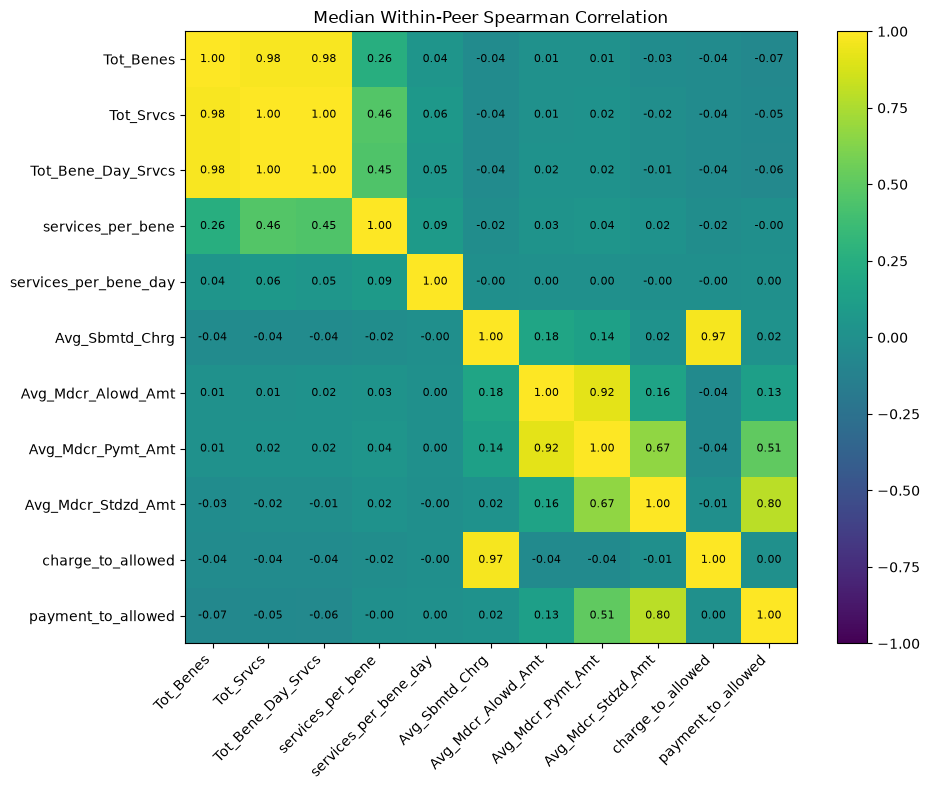

In [15]:
fig, ax = plt.subplots(
    figsize=(10, 8)
)

im = ax.imshow(
    median_spearman.values,
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    range(len(candidate_features))
)

ax.set_yticks(
    range(len(candidate_features))
)

ax.set_xticklabels(
    candidate_features,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    candidate_features
)

for i in range(len(candidate_features)):
    for j in range(len(candidate_features)):

        ax.text(
            j,
            i,
            f"{median_spearman.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title(
    "Median Within-Peer Spearman Correlation"
)

plt.colorbar(im)

plt.tight_layout()
plt.show()

In [16]:
REDUNDANCY_FLAG = 0.85

redundant_pairs = []

for i in range(len(candidate_features)):

    for j in range(i + 1, len(candidate_features)):

        rho = median_abs_spearman.iloc[i, j]

        if rho >= REDUNDANCY_FLAG:

            redundant_pairs.append({
                "feature_1":
                    candidate_features[i],

                "feature_2":
                    candidate_features[j],

                "median_abs_spearman":
                    rho
            })

redundant_pairs = pd.DataFrame(
    redundant_pairs
).sort_values(
    "median_abs_spearman",
    ascending=False
)

redundant_pairs

,feature_1,feature_2,median_abs_spearman
2,Tot_Srvcs,Tot_Bene_Day_Srvcs,0.999983
1,Tot_Benes,Tot_Bene_Day_Srvcs,0.981320
0,Tot_Benes,Tot_Srvcs,0.979216
3,Avg_Sbmtd_Chrg,charge_to_allowed,0.971215
4,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,0.917342


In [17]:
N_ESTIMATORS = 200
MODEL_SEED = 42


def fit_iforest(
    train_df,
    features,
    seed=MODEL_SEED
):

    X_train = np.log1p(
        train_df[features].copy()
    )

    model = IsolationForest(
        n_estimators=N_ESTIMATORS,
        max_samples="auto",
        contamination="auto",
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_train)

    return model

In [18]:
def score_iforest(
    model,
    data,
    features
):

    X = np.log1p(
        data[features].copy()
    )

    scores = -model.score_samples(X)

    return pd.Series(
        scores,
        index=data.index
    )

In [19]:
TRAIN_FRAC = 0.70
SPLIT_SEED = 123


def split_peer(group):

    train = group.sample(
        frac=TRAIN_FRAC,
        random_state=SPLIT_SEED
    )

    evaluation = group.drop(
        index=train.index
    )

    return train, evaluation

In [20]:
SHAP_PEERS = 10
SHAP_BACKGROUND_SIZE = 20
SHAP_EXPLAIN_SIZE = 40
SHAP_PERMUTATIONS = 5

shap_results = []

shap_peer_items = list(
    peer_data.items()
)[:SHAP_PEERS]

In [21]:
for peer_number, (peer_key, group) in enumerate(
    shap_peer_items,
    start=1
):

    train, evaluation = split_peer(group)

    model = fit_iforest(
        train,
        candidate_features
    )

    X_train = np.log1p(
        train[candidate_features]
    )

    X_eval = np.log1p(
        evaluation[candidate_features]
    )

    background = X_train.sample(
        n=min(
            SHAP_BACKGROUND_SIZE,
            len(X_train)
        ),
        random_state=42
    )

    explain_data = X_eval.sample(
        n=min(
            SHAP_EXPLAIN_SIZE,
            len(X_eval)
        ),
        random_state=42
    )

    def anomaly_function(x):

        x_df = pd.DataFrame(
            x,
            columns=candidate_features
        )

        return -model.score_samples(
            x_df
        )

    explainer = shap.Explainer(
        anomaly_function,
        background,
        algorithm="permutation",
        feature_names=candidate_features,
        seed=42
    )

    max_evals = (
        SHAP_PERMUTATIONS
        * 2
        * len(candidate_features)
        + 1
    )

    shap_values = explainer(
        explain_data,
        max_evals=max_evals
    )

    mean_abs_shap = (
        np.abs(shap_values.values)
        .mean(axis=0)
    )

    total_importance = (
        mean_abs_shap.sum()
    )

    for feature, importance in zip(
        candidate_features,
        mean_abs_shap
    ):

        shap_results.append({
            "peer": peer_key,
            "feature": feature,
            "mean_abs_shap": importance,
            "importance_share":
                importance /
                total_importance
        })

    print(
        f"Finished SHAP peer "
        f"{peer_number}/{len(shap_peer_items)}"
    )

Finished SHAP peer 1/10
Finished SHAP peer 2/10
Finished SHAP peer 3/10
Finished SHAP peer 4/10
Finished SHAP peer 5/10
Finished SHAP peer 6/10
Finished SHAP peer 7/10
Finished SHAP peer 8/10
Finished SHAP peer 9/10
Finished SHAP peer 10/10


In [22]:
shap_results = pd.DataFrame(
    shap_results
)

shap_summary = (
    shap_results
    .groupby("feature")
    .agg(
        mean_importance_share=(
            "importance_share",
            "mean"
        ),
        median_importance_share=(
            "importance_share",
            "median"
        ),
        std_importance_share=(
            "importance_share",
            "std"
        )
    )
    .sort_values(
        "mean_importance_share",
        ascending=False
    )
)

shap_summary

,mean_importance_share,median_importance_share,std_importance_share
feature,,,
services_per_bene,0.117157,0.111487,0.065444
Avg_Mdcr_Stdzd_Amt,0.110630,0.127258,0.043499
Avg_Mdcr_Alowd_Amt,0.100813,0.109927,0.033051
Avg_Mdcr_Pymt_Amt,0.093979,0.090846,0.024833
charge_to_allowed,0.093214,0.092548,0.017887
Tot_Bene_Day_Srvcs,0.091752,0.088956,0.013229
Tot_Benes,0.089465,0.091292,0.014679
payment_to_allowed,0.086561,0.089884,0.038087
Avg_Sbmtd_Chrg,0.082494,0.080802,0.015339


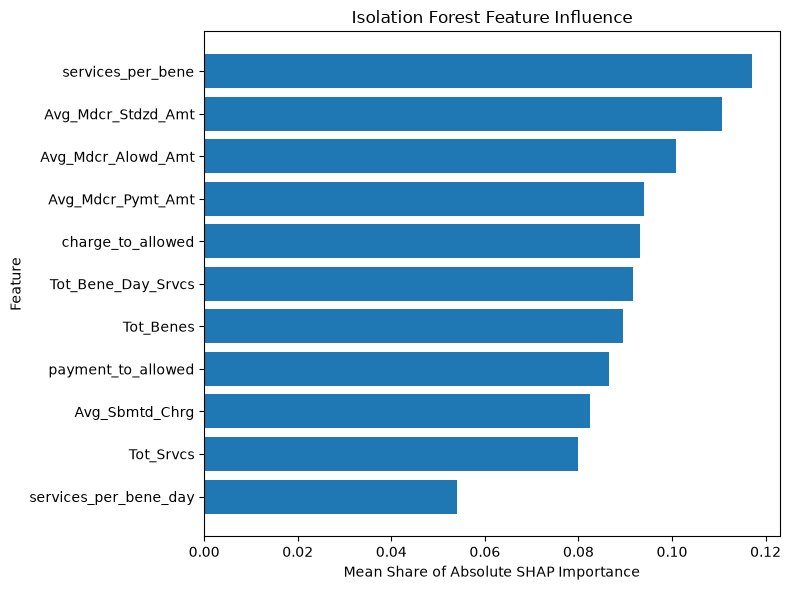

In [23]:
plot_shap = (
    shap_summary
    .sort_values(
        "mean_importance_share"
    )
)

plt.figure(figsize=(8, 6))

plt.barh(
    plot_shap.index,
    plot_shap[
        "mean_importance_share"
    ]
)

plt.xlabel(
    "Mean Share of Absolute SHAP Importance"
)

plt.ylabel("Feature")

plt.title(
    "Isolation Forest Feature Influence"
)

plt.tight_layout()
plt.show()

In [24]:
def top_k_jaccard(
    scores_a,
    scores_b,
    top_pct=0.05
):

    n_top = max(
        1,
        int(
            len(scores_a)
            * top_pct
        )
    )

    top_a = set(
        scores_a.nlargest(
            n_top
        ).index
    )

    top_b = set(
        scores_b.nlargest(
            n_top
        ).index
    )

    intersection = len(
        top_a & top_b
    )

    union = len(
        top_a | top_b
    )

    return intersection / union

In [25]:
ablation_results = []

for peer_number, (peer_key, group) in enumerate(
    peer_data.items(),
    start=1
):

    train, evaluation = split_peer(
        group
    )

    # Full candidate model
    full_model = fit_iforest(
        train,
        candidate_features
    )

    full_scores = score_iforest(
        full_model,
        evaluation,
        candidate_features
    )

    # Remove one feature at a time
    for removed_feature in candidate_features:

        reduced_features = [
            feature
            for feature in candidate_features
            if feature != removed_feature
        ]

        reduced_model = fit_iforest(
            train,
            reduced_features
        )

        reduced_scores = score_iforest(
            reduced_model,
            evaluation,
            reduced_features
        )

        rho, _ = spearmanr(
            full_scores,
            reduced_scores
        )

        jaccard_5 = top_k_jaccard(
            full_scores,
            reduced_scores,
            top_pct=0.05
        )

        ablation_results.append({
            "peer": peer_key,
            "removed_feature":
                removed_feature,
            "spearman_vs_full":
                rho,
            "top5_jaccard":
                jaccard_5
        })

    print(
        f"Finished peer "
        f"{peer_number}/{len(peer_data)}"
    )

Finished peer 1/50
Finished peer 2/50
Finished peer 3/50
Finished peer 4/50
Finished peer 5/50
Finished peer 6/50
Finished peer 7/50
Finished peer 8/50
Finished peer 9/50
Finished peer 10/50
Finished peer 11/50
Finished peer 12/50
Finished peer 13/50
Finished peer 14/50
Finished peer 15/50
Finished peer 16/50
Finished peer 17/50
Finished peer 18/50
Finished peer 19/50
Finished peer 20/50
Finished peer 21/50
Finished peer 22/50
Finished peer 23/50
Finished peer 24/50
Finished peer 25/50
Finished peer 26/50
Finished peer 27/50
Finished peer 28/50
Finished peer 29/50
Finished peer 30/50
Finished peer 31/50
Finished peer 32/50
Finished peer 33/50
Finished peer 34/50
Finished peer 35/50
Finished peer 36/50
Finished peer 37/50
Finished peer 38/50
Finished peer 39/50
Finished peer 40/50
Finished peer 41/50
Finished peer 42/50
Finished peer 43/50
Finished peer 44/50
Finished peer 45/50
Finished peer 46/50
Finished peer 47/50
Finished peer 48/50
Finished peer 49/50
Finished peer 50/50


In [26]:
ablation_results = pd.DataFrame(
    ablation_results
)

ablation_summary = (
    ablation_results
    .groupby("removed_feature")
    .agg(
        mean_spearman=(
            "spearman_vs_full",
            "mean"
        ),
        median_spearman=(
            "spearman_vs_full",
            "median"
        ),
        std_spearman=(
            "spearman_vs_full",
            "std"
        ),
        mean_top5_jaccard=(
            "top5_jaccard",
            "mean"
        ),
        median_top5_jaccard=(
            "top5_jaccard",
            "median"
        )
    )
    .sort_values(
        "mean_spearman"
    )
)

ablation_summary

,mean_spearman,median_spearman,std_spearman,mean_top5_jaccard,median_top5_jaccard
removed_feature,,,,,
services_per_bene,0.954417,0.961128,0.025370,0.709232,0.735088
Avg_Sbmtd_Chrg,0.961654,0.963883,0.010575,0.713936,0.716117
payment_to_allowed,0.965085,0.967415,0.014129,0.650453,0.647059
charge_to_allowed,0.966309,0.968407,0.011068,0.708264,0.692308
Avg_Mdcr_Alowd_Amt,0.968638,0.968545,0.007916,0.654292,0.666667
Avg_Mdcr_Stdzd_Amt,0.970047,0.972362,0.010775,0.647028,0.661905
Avg_Mdcr_Pymt_Amt,0.973740,0.974223,0.005996,0.657415,0.666667
services_per_bene_day,0.974296,0.978065,0.012592,0.748552,0.764706
Tot_Benes,0.977274,0.979354,0.007759,0.732270,0.737986
